# E01 · The angular spectrum method

Follow a slit field into space by changing the representation: separate its directions, advance their phases, and add them back.

<!-- course-preparation:start -->
## Before this lab

Use these focused refreshers if an idea is unfamiliar; you do not need to complete each linked course.

- **Complex amplitudes and phase:** Read a wave as A exp(iφ) and intensity as |u|². Used here: The propagation factor changes each component's phase and, for evanescent components, its amplitude. [Review: MIT OCW · Complex Arithmetic and Exponentials](https://ocw.mit.edu/courses/18-03sc-differential-equations-fall-2011/pages/unit-i-first-order-differential-equations/complex-arithmetic-and-exponentials/). Read the notes on Euler's formula, polar form, multiplication, and complex conjugation. The differential-equation applications can wait.
- **Fourier transforms and convolution:** Interpret a Fourier transform as a change from position to spatial-frequency components. Used here: Each component represents one transverse wavevector. [Review: TU Delft · Fourier analysis](https://qiweb.tudelft.nl/aoi/fourieranalysis/fourieranalysis/). Use §4.1 for the transform pair, then §4.2.1–4.2.4 for linearity, scaling, shifts, and convolution. Consult §4.2.7 for two successive transforms.
- **Matrices, eigenvectors, and modes:** Recognize a basis expansion and Av = λv. Used here: The film describes plane waves as eigenfunctions of free-space propagation. [Review: MIT OCW · Eigenvalues and Eigenvectors](https://ocw.mit.edu/courses/18-06sc-linear-algebra-fall-2011/pages/least-squares-determinants-and-eigenvalues/eigenvalues-and-eigenvectors/). Start with the lecture summary and one 2 × 2 worked problem. Focus on Av = λv and what changes when a matrix is applied repeatedly.

**Python preparation:** Use complex arrays and FFT frequency bins; keep physical sample spacing separate from array indices.
- [NumPy · The absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html) — Use the sections on array shape, indexing and slicing, basic operations, and broadcasting. Practice changing one parameter and rerunning a cell.
- [NumPy · Discrete Fourier Transform](https://numpy.org/doc/stable/reference/routines.fft.html) — Read Implementation details and Normalization; look up fftfreq, fftshift, and ifftshift as they appear in the notebook.

**Developed here:** Build the angular-spectrum propagator and test its sampling and propagation limits.

[All prerequisites and learning resources](https://vandermode.github.io/optics-in-5-minutes-course/preparation/)
<!-- course-preparation:end -->

**Core lab: 25–30 minutes.** Work through the predictions before running the next cell. Sections labelled optional can be skipped on a first pass. Run all executes both the core and the small CPU extension.

**You will learn to:**

- Interpret a Fourier coefficient as a plane-wave amplitude.
- Predict how wavelength, aperture width, and distance change diffraction.
- Separate physical evanescent decay from numerical aliasing and wrap-around.

**Model:** Scalar, monochromatic propagation in homogeneous free space. The slit is a 1D field invariant in the omitted direction. No vector polarization, material boundary scattering, detector averaging, or noise is modeled. FFT windows are periodic.

This notebook is self-contained. It uses synthetic data, runs on CPU, and needs no repository clone, mounted Drive, API key, or external dataset. The setup installs only missing packages. Figures are displayed as static PNGs and also saved in a local folder for download.


In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ["numpy", "scipy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
FIGURES = Path("e01_figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": False, "figure.constrained_layout.use": True})
def show(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)


Python 3.12.13 | NumPy 2.4.3 | SciPy 1.16.3 | Matplotlib 3.11.2


## 1 · A complex field, then a propagation rule

A complex number encodes an amplitude and phase. Squaring its magnitude gives intensity,
but discards the phase needed for later interference. For a plane wave, substituting
$e^{i(k_xx+k_zz)}$ into the Helmholtz equation gives $k_z^2=k^2-k_x^2$.
The outgoing square root is real for propagating waves and positive imaginary for evanescent waves.

**Predict:** at the same wavelength and distance, which slit makes the broader pattern?
Change width only after recording your prediction. All calculation lengths below are micrometres.

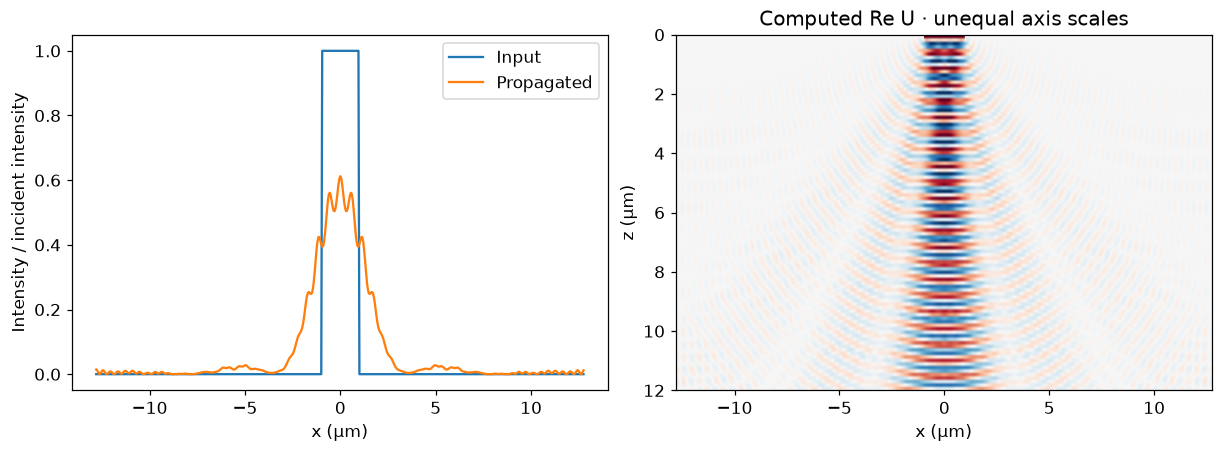

In [2]:
wavelength = 0.55
width = 2.0
distance = 12.0
dx, n = 0.05, 512
x = (np.arange(n)-n//2)*dx
u0 = (abs(x)<width/2).astype(complex)
def asm(field, dx, wavelength, z, fresnel=False):
    axes = [np.fft.fftfreq(size, dx) for size in field.shape]
    grids = np.meshgrid(*axes, indexing="ij")
    transverse = sum((2*np.pi*g)**2 for g in grids)
    k = 2*np.pi/wavelength
    kz = k-transverse/(2*k) if fresnel else np.sqrt(k*k-transverse+0j)
    return np.fft.ifftn(np.fft.fftn(field)*np.exp(1j*z*kz))
u = asm(u0, dx, wavelength, distance)
z_values = np.linspace(0, distance, 101)
history = np.array([asm(u0,dx,wavelength,z) for z in z_values])
fig, ax = plt.subplots(1,2,figsize=(11,4))
ax[0].plot(x,abs(u0)**2,label="Input");ax[0].plot(x,abs(u)**2,label="Propagated")
ax[0].set(xlabel="x (μm)",ylabel="Intensity / incident intensity");ax[0].legend()
ax[1].imshow(history.real,extent=[x[0],x[-1],distance,0],aspect="auto",cmap="RdBu_r",vmin=-1,vmax=1)
ax[1].set(xlabel="x (μm)",ylabel="z (μm)",title="Computed Re U · unequal axis scales")
show(fig,"01-slit-propagation")

## 2 · Verify a case whose answer is known

A Fourier-grid plane wave is an eigenfunction: it retains its shape and gains one analytic
propagation factor. This is a stronger test than comparing two similar-looking plots.
At zero distance the operator must be the identity. On the propagating band it must preserve
the squared field norm because every multiplier has magnitude one.

In [3]:
assert np.max(abs(asm(u0,dx,wavelength,0)-u0)) < 1e-12
mode = 7
fx = mode/(n*dx)
plane = np.exp(2j*np.pi*fx*np.arange(n)*dx)
expected = plane*np.exp(1j*distance*np.sqrt((2*np.pi/wavelength)**2-(2*np.pi*fx)**2))
plane_error = np.max(abs(asm(plane,dx,wavelength,distance)-expected))
random = np.random.default_rng(11)
spec = random.normal(size=n)+1j*random.normal(size=n)
frequencies = np.fft.fftfreq(n,dx)
spec[abs(frequencies)>=1/wavelength] = 0
bandlimited = np.fft.ifft(spec)
power_error = abs(np.vdot(asm(bandlimited,dx,wavelength,3),asm(bandlimited,dx,wavelength,3)).real/np.vdot(bandlimited,bandlimited).real-1)
evanescent_mode = int(np.ceil(1.2/wavelength*n*dx))
ev_fx = evanescent_mode/(n*dx)
ev = np.exp(2j*np.pi*ev_fx*np.arange(n)*dx)
ev_z = .1
decay = np.exp(-ev_z*np.sqrt((2*np.pi*ev_fx)**2-(2*np.pi/wavelength)**2))
ev_error = np.max(abs(asm(ev,dx,wavelength,ev_z)-ev*decay))
assert plane_error < 1e-11 and power_error < 1e-12 and ev_error < 1e-11
print("Plane-wave error:",plane_error,"Power error:",power_error,"Evanescent error:",ev_error)

Plane-wave error: 7.421074851107613e-15 Power error: 2.220446049250313e-16 Evanescent error: 1.840854420250902e-14


## 3 · The FFT window repeats

Padding changes the distance to periodic copies; it does not change the sample spacing.
The following deliberately long propagation compares one, two, and four window widths.
The four-window answer is a refinement reference, not an exact infinite-domain solution.
**Predict:** which disagreement should shrink when padding increases?

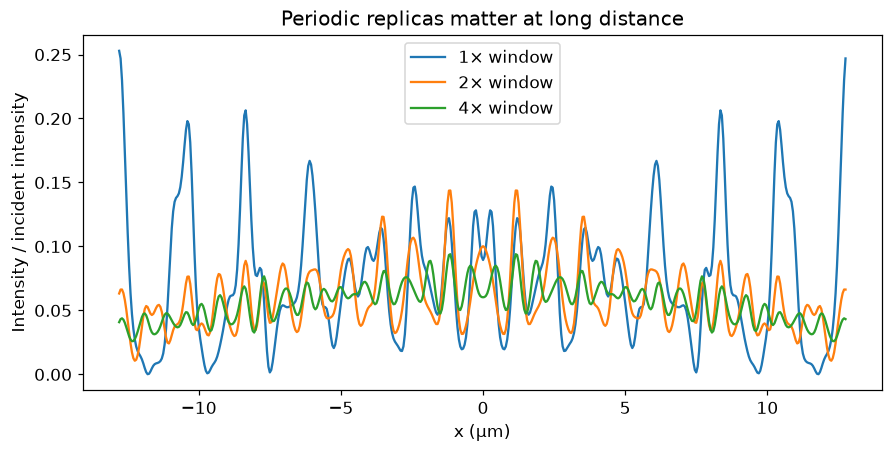

Field errors against 4× reference: [np.float64(0.5583740524873434), np.float64(0.2349645302596987)]


In [4]:
long_z = 100.
outputs = []
for factor in [1,2,4]:
    margin = (factor-1)*n//2
    padded = np.pad(u0,(margin,margin))
    full = asm(padded,dx,wavelength,long_z)
    outputs.append(full[margin:margin+n])
errors = [np.linalg.norm(v-outputs[-1])/np.linalg.norm(outputs[-1]) for v in outputs[:2]]
fig,ax=plt.subplots(figsize=(8,4))
for factor,v in zip([1,2,4],outputs):ax.plot(x,abs(v)**2,label=f"{factor}× window")
ax.set(xlabel="x (μm)",ylabel="Intensity / incident intensity",title="Periodic replicas matter at long distance");ax.legend()
show(fig,"02-padding")
print("Field errors against 4× reference:",errors)

## Optional extension · Two dimensions and a paraxial approximation

The square root now contains both transverse frequencies. Fresnel propagation replaces it
with a paraboloid. Keep the grid fixed while changing the model, then refine the grid separately.
Negative-distance inversion is intentionally excluded: it can exponentially amplify evanescent noise.

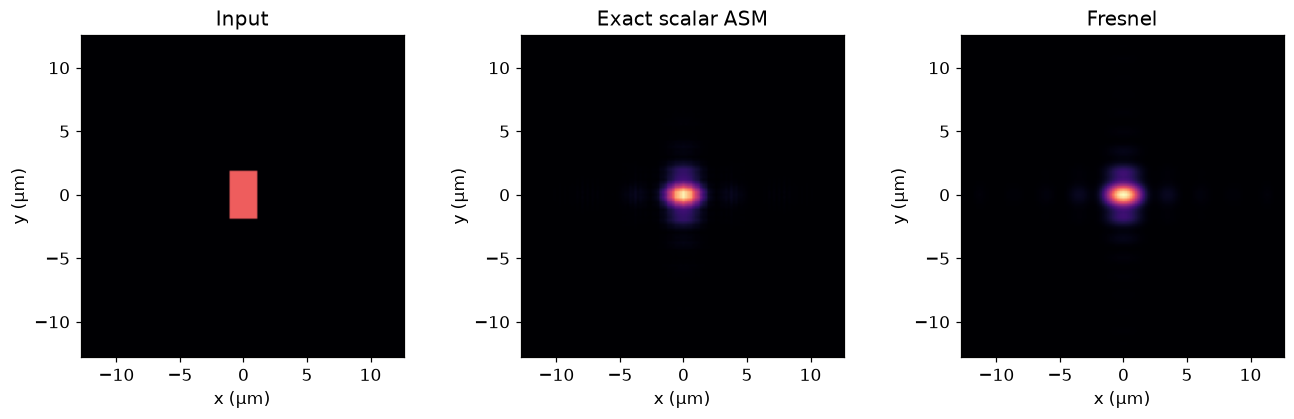

Exact/Fresnel relative intensity difference: 0.07085636402455406


In [5]:
n2, dx2, z2 = 128, .2, 10.
axis = (np.arange(n2)-n2//2)*dx2
X,Y=np.meshgrid(axis,axis)
aperture=((abs(X)<1.2)&(abs(Y)<2.0)).astype(complex)
exact=asm(aperture,dx2,wavelength,z2)
paraxial=asm(aperture,dx2,wavelength,z2,True)
fig,ax=plt.subplots(1,3,figsize=(12,3.7))
vmax=max(np.max(abs(exact)**2),np.max(abs(paraxial)**2))
for a,v,title in zip(ax,[aperture,exact,paraxial],["Input","Exact scalar ASM","Fresnel"]):
    a.imshow(abs(v)**2,extent=[axis[0],axis[-1],axis[0],axis[-1]],origin="lower",vmin=0,vmax=vmax,cmap="magma")
    a.set(title=title,xlabel="x (μm)",ylabel="y (μm)")
show(fig,"03-two-dimensional")
print("Exact/Fresnel relative intensity difference:",np.linalg.norm(abs(exact)**2-abs(paraxial)**2)/np.linalg.norm(abs(exact)**2))

## A short lab report

**1. Compare two widths.** Predict the ratio of far-field angular widths, then measure their first minima or central-band widths.

**2. Separate numerical errors.** Change padding and sample spacing independently. Explain which fixes wrap-around and which extends Nyquist.

**3. Test an eigenfunction.** Propagate a single Fourier-grid plane wave and compare it with its analytic phase factor.

### Worked reasoning

**Compare two widths.** Halving the slit width doubles the ideal far-field angular scale; a finite-distance pattern need not obey the far-field estimate exactly.

**Separate numerical errors.** Padding separates periodic replicas; smaller pixels represent higher spatial frequencies. Neither replaces checking convergence.

**Test an eigenfunction.** A grid-aligned plane wave keeps its transverse shape. Its coefficient gains e^(i k_z z), and its norm stays constant when k_z is real.

### Ten-point rubric

Prediction and reasoning: 2; reproducible parameters, units, and plots: 3; quantitative validation: 3; limitations and interpretation: 2.

## References

- [TU Delft · Wavefield propagation](https://qiweb.tudelft.nl/aoi/wavefieldpropagation/wavefieldpropagation/)
- [NumPy · Fourier transforms and normalization](https://numpy.org/doc/stable/reference/routines.fft.html)

## Save your figures

The final cell creates a ZIP of the computed PNGs. In Colab, use the Files sidebar to download it if an output frame or link is blocked. Saved notebook outputs and the public lesson's figure download provide another viewing route.

In [6]:
import zipfile
archive = FIGURES.with_suffix(".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(FIGURES.glob("*.png")):
        bundle.write(file, file.name)
print("Saved", len(list(FIGURES.glob("*.png"))), "figures in", archive)
display(FileLink(str(archive)))


Saved 3 figures in e01_figures.zip


/tmp/optics-notebooks-xppq4daw/E01/e01_figures.zip